# code_016 · Kinds and sources of uncertainty

**Book:** Chapter 3, section 3.5. **Purpose:** an independent probability/statistics laboratory with synthetic populations and declared measurement models. No numerical result is evidence of structural safety, an empirical causal effect or production reliability.

Use the repository [quickstart](../README.md), select the [pinned environment](../requirements-lock.txt), restart and run every cell. Reference target: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, CPU only on macOS ARM64. All inputs, generators and helper definitions are here. Normal runs require no network, data files, API keys, GPU or private imports. Allow a minute for execution and 30–60 minutes for interpretation/exercises. Actual versions and time appear below and in [run evidence](../CHAPTER_03_EXECUTION.md).

Read predictions before output. Sampling assumptions, priors, numerical simulation budgets and decision margins have different roles; they are not all model hyperparameters. These are scoped concept laboratories, not full estimator-constructor guides. The [traceability guide](../CHAPTER_03_GUIDE.md) maps mechanisms and exercises, and the [stable registry](../CODE_EXAMPLES.md#code_016) preserves this ID. Synthetic algebra/population checks need no learned train/test split; any fitted prediction experiment below states its calibration and assessment boundaries.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from scipy import stats,special
from IPython.display import display
START=time.perf_counter();SEED=316
rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,
'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,
'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 316


<a id="decomposition"></a>
## A variance decomposition under a declared model

Let p|data ~ Beta(6,34) and Y|p ~ Bernoulli(p). E[p(1-p)] + Var(p) = mu*(1-mu). The first term represents conditional outcome variation; the second uncertainty about the conditional mean. This equality is about this model, not proof that real uncertainty has been completely separated. More information about p need not remove randomness of a future binary outcome.

**Predict:** should a narrow credible interval around p=.15 imply the next Y is numerically near .15?


In [2]:
aa,bb=6.,34.;mean_p=aa/(aa+bb);parameter_var=aa*bb/((aa+bb)**2*(aa+bb+1))
expected_conditional_var=aa*bb/((aa+bb)*(aa+bb+1))
total_var=mean_p*(1-mean_p)
assert np.isclose(parameter_var+expected_conditional_var,total_var)
print({'expected_outcome_variance':expected_conditional_var,'parameter_mean_variance':parameter_var,'predictive_variance':total_var})
RESULTS['variance_components']={'outcome':float(expected_conditional_var),'parameter':float(parameter_var),'total':float(total_var)}


{'expected_outcome_variance': 0.12439024390243902, 'parameter_mean_variance': 0.0031097560975609758, 'predictive_variance': 0.1275}


<a id="mean-outcome"></a>
## Interval for a mean versus one new observation

Assume iid normal readings with true mu=1 mm and genuinely known sigma=.2 mm. Use z=norm.ppf(.975). The mean-interval half-width is z*sigma/sqrt(n); the future-observation half-width is z*sigma*sqrt(1+1/n). The latter uses independence of a future observation and the estimation sample. If sigma were estimated, additional small-sample uncertainty would require a different construction. These are explicit normal-model calculations, not field guarantees.

**Predict:** which half-width tends to zero as n grows? Why is using the mean interval on a future reading a category error?


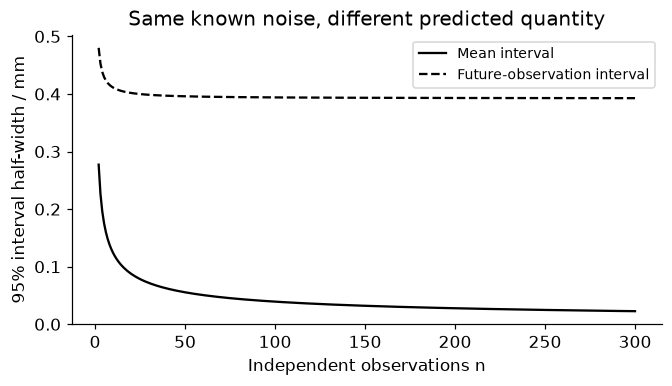

Mean coverage: 0.94925 future coverage: 0.9512 wrong mean interval used for outcome: 0.2976


In [3]:
sigma=.2;z=stats.norm.ppf(.975);ns=np.arange(2,301)
mean_half=z*sigma/np.sqrt(ns);outcome_half=z*sigma*np.sqrt(1+1/ns)
assert np.all(outcome_half>mean_half) and mean_half[-1]<mean_half[0]
fig,ax=plt.subplots(figsize=(6,3.4));ax.plot(ns,mean_half,'k-',label='Mean interval');ax.plot(ns,outcome_half,'k--',label='Future-observation interval')
ax.set(xlabel='Independent observations n',ylabel='95% interval half-width / mm',title='Same known noise, different predicted quantity');ax.legend(fontsize=9);plt.show()
replications=20000;n=25;means=rng.normal(1.,sigma/np.sqrt(n),replications);future=rng.normal(1.,sigma,replications)
mean_coverage=np.mean(abs(means-1.)<=z*sigma/np.sqrt(n))
future_coverage=np.mean(abs(future-means)<=z*sigma*np.sqrt(1+1/n))
wrong_future_coverage=np.mean(abs(future-means)<=z*sigma/np.sqrt(n))
assert .93<mean_coverage<.97 and .93<future_coverage<.97 and wrong_future_coverage<.4
print('Mean coverage:',mean_coverage,'future coverage:',future_coverage,'wrong mean interval used for outcome:',wrong_future_coverage)
RESULTS['normal_interval_coverages']={'mean':float(mean_coverage),'future':float(future_coverage),'wrong_mean_band_for_future':float(wrong_future_coverage)}


<a id="noise-bias"></a>
## Averaging an offset sensor

Observe a fixed latent response of 1 mm with an offset .15 mm plus independent normal noise sd .2 mm. Repeated readings reduce uncertainty about the *biased measured mean*. They do not remove the offset. Noise labeled irreducible is relative to the current measurement/information set; an informative new covariate or calibration can change it.

**Predict:** why might the measured mean be estimated very precisely while being an inaccurate estimate of the physical response?


In [4]:
latent=1.;offset=.15;readings=latent+offset+rng.normal(0,.2,30000)
measured_mean=readings.mean();se=.2/np.sqrt(len(readings))
assert abs(measured_mean-(latent+offset))<.01 and abs(measured_mean-latent)>20*se
print('Measured mean [mm]:',measured_mean,'noise-only SE [mm]:',se,'latent [mm]:',latent)
RESULTS['biased_measured_mean_mm']=float(measured_mean);RESULTS['noise_only_SE_mm']=float(se)


Measured mean [mm]: 1.1504498613898575 noise-only SE [mm]: 0.0011547005383792516 latent [mm]: 1.0


<a id="material-shift"></a>
## A precisely fitted relationship can fail on a new material

Calibration: 80 independent load/deflection pairs for material A, load 100–1000 N, true compliance .002 mm/N and independent known normal measurement sigma=.2 mm. Fit a physically motivated through-origin line using calibration outcomes only. The known-sigma slope variance is sigma²/sum(P²). A fixed held-out A set evaluates in-domain prediction; a separate B stress set changes true compliance to .003 mm/N at the same load range. No B outcomes enter fitting, interval construction or model selection.

For a new measurement at P, the conditional linear-model prediction half-width is z*sqrt(sigma²+P²*Var(c_hat)). The support flag 'unseen material' is a warning, not a calibrated probability of model failure. This toy model deliberately omits misspecification/shift from its interval, so the stress test can expose that limit.

**Predict:** will more precise A slope estimation make the B relationship correct? What scientific measurements could support a valid B model?


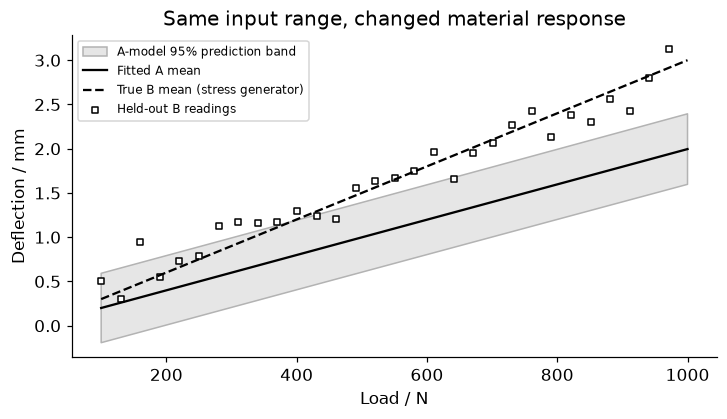

Fitted compliance [mm/N]: 0.0019955552984235883 A coverage: 0.9533333333333334 B coverage: 0.3333333333333333


In [5]:
noise=.2;true_A=.002;true_B=.003
load_train=np.linspace(100.,1000.,80);y_train=true_A*load_train+rng.normal(0,noise,len(load_train))
compliance=(load_train@y_train)/(load_train@load_train);slope_var=noise**2/(load_train@load_train)
load_test=np.linspace(100.,1000.,600);prediction=compliance*load_test
# Assessment outcomes are generated only after the fit and interval rule are fixed.
y_A=true_A*load_test+rng.normal(0,noise,len(load_test));y_B=true_B*load_test+rng.normal(0,noise,len(load_test))
half=z*np.sqrt(noise**2+load_test**2*slope_var)
cover_A=np.mean(abs(y_A-prediction)<=half);cover_B=np.mean(abs(y_B-prediction)<=half)
assert .9<cover_A<.99 and cover_B<cover_A-.3
assert abs(compliance-true_A)<4*np.sqrt(slope_var)
fig,ax=plt.subplots(figsize=(6.5,3.7));ax.fill_between(load_test,prediction-half,prediction+half,color='.9',hatch='//',edgecolor='.7',label='A-model 95% prediction band')
ax.plot(load_test,prediction,'k-',label='Fitted A mean');ax.plot(load_test,true_B*load_test,'k--',label='True B mean (stress generator)')
ax.scatter(load_test[::20],y_B[::20],marker='s',s=20,facecolors='white',edgecolors='black',label='Held-out B readings')
ax.set(xlabel='Load / N',ylabel='Deflection / mm',title='Same input range, changed material response');ax.legend(fontsize=8);plt.show()
print('Fitted compliance [mm/N]:',compliance,'A coverage:',cover_A,'B coverage:',cover_B)
RESULTS['fitted_compliance_mm_per_N']=float(compliance);RESULTS['material_A_coverage']=float(cover_A);RESULTS['material_B_coverage']=float(cover_B)


<a id="ledger"></a>
## Name what each interval excludes

A model can be misspecified within the original population; deployment can additionally shift the input distribution, response relationship or measurement process. The A/B experiment holds the load range fixed while changing the conditional response. Overall coverage in A cannot validate B. If an interval band is wide, also ask whether its width is useful for a decision.

The table is a checked semantic worksheet, not a trained uncertainty estimator. Parameter intervals, bootstrap intervals, predictive intervals and an unseen-material flag make different claims.


In [6]:
ledger=pd.DataFrame([
 ['sensor average','measured mean','iid reading noise','fixed calibration offset'],
 ['beta credible interval','common recorded event probability','posterior parameter uncertainty','label error and changed population'],
 ['building bootstrap','equal-building fixed-predictor error contrast','assessment building sampling','retraining and model selection'],
 ['A prediction interval','one new A measurement under linear model','known noise and slope uncertainty','new-material compliance and unknown bias'],
 ['unseen-material flag','support membership','observed label support','size or probability of prediction error']
],columns=['report','quantity','includes','excludes'])
assert len(ledger)==5 and ledger['excludes'].notna().all();display(ledger)


,report,quantity,includes,excludes
0,sensor average,measured mean,iid reading noise,fixed calibration offset
1,beta credible interval,common recorded event probability,posterior parameter uncertainty,label error and changed population
2,building bootstrap,equal-building fixed-predictor error contrast,assessment building sampling,retraining and model selection
3,A prediction interval,one new A measurement under linear model,known noise and slope uncertainty,new-material compliance and unknown bias
4,unseen-material flag,support membership,observed label support,size or probability of prediction error


<a id="exercises"></a>
## Exercises and optional hints

1. Increase the beta posterior concentration at fixed mean. Check that parameter variance shrinks while one-outcome variance approaches mu*(1-mu), not zero.
2. Estimate sigma rather than treating it as known. Derive an appropriate normal-model t interval and state the degrees of freedom.
3. Add a calibration offset or load-dependent variance to material A. Explain which interval assumption fails.
4. Collect a new, representative B calibration sample and reserve a new B final assessment. Do not retune on the already viewed B stress outcomes and call them fresh evidence.
5. Change only the load distribution, then separately change compliance. Label input shift versus conditional-response shift and inspect group/range coverage.
6. Write a one-paragraph uncertainty statement naming quantity, population, conditioning information, method, sources included and important exclusions.

**Hints:** ensemble agreement alone is not calibration. A support flag does not supply a guaranteed interval. Finite-sample parameter uncertainty, measurement error, misspecification and shift can coexist and need different evidence. Predictive coverage and width should be assessed on relevant held-out observations, including adequately sampled subgroups.

**Troubleshooting:** never substitute a mean confidence interval for an individual prediction interval. A fitted material-A model has no empirical B training evidence. [NIST confidence-interval interpretation](https://www.itl.nist.gov/div898/handbook/prc/section1/prc14.htm) supports the repeated-sampling convention; the normal prediction formula and variance identity are derived in the chapter.


In [7]:
summary={'example_id':'code_016','seed':SEED,'versions':VERSIONS,
'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['predictive variance decomposition', 'mean versus future-outcome intervals', 'measurement noise versus bias', 'training-only compliance estimate', 'held-out material shift', 'coverage and interval scope ledger'],
'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["predictive variance decomposition", "mean versus future-outcome intervals", "measurement noise versus bias", "training-only compliance estimate", "held-out material shift", "coverage and interval scope ledger"], "elapsed_seconds": 0.163, "example_id": "code_016", "hardware": "Darwin arm64 CPU", "results": {"biased_measured_mean_mm": 1.1504498613898575, "fitted_compliance_mm_per_N": 0.0019955552984235883, "material_A_coverage": 0.9533333333333334, "material_B_coverage": 0.3333333333333333, "noise_only_SE_mm": 0.0011547005383792516, "normal_interval_coverages": {"future": 0.9512, "mean": 0.94925, "wrong_mean_band_for_future": 0.2976}, "variance_components": {"outcome": 0.12439024390243902, "parameter": 0.0031097560975609758, "total": 0.1275}}, "seed": 316, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
